## Cell 1: imports and data

In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

c = "cleaned/"
orders      = pd.read_csv(c + "orders.csv",      parse_dates=["order_date", "delivered_date"])
order_items = pd.read_csv(c + "order_items.csv")
customers   = pd.read_csv(c + "customers.csv",   parse_dates=["registration_date", "last_login_date"])
payments    = pd.read_csv(c + "payments.csv",    parse_dates=["payment_date", "refund_date"])
returns     = pd.read_csv(c + "returns.csv",     parse_dates=["return_date", "refund_date"])
inventory   = pd.read_csv(c + "inventory.csv",   parse_dates=["last_restocked_date"])

kpis = {}   # every KPI is stored here; we build the summary table at the end

## KPI 1: GMV

In [2]:
gmv = orders["final_amount"].sum()
kpis["GMV (Rs. crore)"] = round(float(gmv) / 1e7, 2)
print(f"GMV: Rs. {gmv:,.0f}  (Rs. {gmv / 1e7:,.2f} crore)")

GMV: Rs. 3,147,385,545  (Rs. 314.74 crore)


**Observation:** IndiaKart's total order value over the two years is Rs. 314.74 crore, about Rs. 13 crore a month. This counts every order placed, including cancelled and returned ones, so it overstates the money the business actually earned.

## KPI 2: Net Revenue

In [3]:
delivered = orders[orders["status"] == "Delivered"]
net_revenue = delivered["final_amount"].sum()
kpis["Net Revenue (Rs. crore)"] = round(float(net_revenue) / 1e7, 2)
print(f"Net Revenue: Rs. {net_revenue:,.0f}  (Rs. {net_revenue / 1e7:,.2f} crore)")
print(f"Net Revenue is {net_revenue / gmv * 100:.1f}% of GMV")

Net Revenue: Rs. 2,053,858,612  (Rs. 205.39 crore)
Net Revenue is 65.3% of GMV


**Observation:** Net revenue from delivered orders is Rs. 205.39 crore, which is only 65.3% of GMV. About Rs. 109 crore of order value never became delivered revenue, because it sits in cancelled, returned or still-in-progress orders.

## KPI 3: AOV

In [4]:
aov = net_revenue / len(delivered)
kpis["AOV (Rs.)"] = round(float(aov))
print(f"Delivered orders: {len(delivered):,}")
print(f"AOV: Rs. {aov:,.0f}")

Delivered orders: 32,499
AOV: Rs. 63,198


**Observation:** The average delivered order is worth Rs. 63,198, a high figure that is likely driven by Electronics, which brings in about 58% of revenue. Raising basket size matters less here than converting more orders into deliveries.

## KPI 4: Cancellation Rate

In [5]:
cancelled = (orders["status"] == "Cancelled").sum()
cancel_rate = cancelled / len(orders) * 100
kpis["Cancellation Rate (%)"] = round(float(cancel_rate), 1)
print(f"Cancelled orders: {cancelled:,} of {len(orders):,}")
print(f"Cancellation Rate: {cancel_rate:.1f}%  (target < 10%)")

Cancelled orders: 5,996 of 50,000
Cancellation Rate: 12.0%  (target < 10%)


**Observation:** The cancellation rate is 12.0% (5,996 of 50,000 orders), about 2 percentage points above the 10% target. That means roughly 1 in 8 orders is lost, so reducing cancellations is a clear way to recover revenue.

## KPI 5: Return Rate

In [6]:
n_ret = len(returns)
n_del = len(delivered)

# Formula from the brief: return records / delivered orders
rr_brief = n_ret / n_del * 100
print(f"Return records: {n_ret:,}")
print(f"Delivered orders: {n_del:,}")
print(f"Return Rate (brief formula): {rr_brief:.1f}%  (target < 8%)")
kpis["Return Rate (%) - brief formula"] = round(float(rr_brief), 1)

# Which order status do the returns belong to?
ret_status = returns.merge(orders[["order_id", "status"]], on="order_id", how="left")
by_status = ret_status["status"].value_counts().rename("returns").to_frame()
by_status["share_%"] = by_status["returns"] / n_ret * 100
print(by_status)

# Cleaner version: only returns on Delivered orders
ret_on_del = (ret_status["status"] == "Delivered").sum()
rr_clean = ret_on_del / n_del * 100
print(f"Returns on Delivered orders: {ret_on_del:,}")
print(f"Return Rate (Delivered orders only): {rr_clean:.1f}%")
kpis["Return Rate (%) - Delivered orders only"] = round(float(rr_clean), 1)

odd = ret_status["status"].isin(["Cancelled", "Shipped", "Processing"]).sum()
print(f"Returns linked to Cancelled/Shipped/Processing orders: {odd:,} ({odd / n_ret * 100:.1f}%)")

Return records: 10,000
Delivered orders: 32,499
Return Rate (brief formula): 30.8%  (target < 8%)
           returns  share_%
status                     
Delivered     4327    43.27
Returned      3933    39.33
Cancelled     1067    10.67
Shipped        673     6.73
Returns on Delivered orders: 4,327
Return Rate (Delivered orders only): 13.3%
Returns linked to Cancelled/Shipped/Processing orders: 1,740 (17.4%)


**Observation:** By the brief's formula the return rate is 30.8%, far above the 8% target. However, 1,740 of the 10,000 return records belong to Cancelled or Shipped orders, which cannot logically be returned, so counting only returns on Delivered orders the rate is 13.3%, which is still above target.

## KPI 6: Customer Lifetime Value

In [7]:
clv = (customers.groupby("segment")
       .agg(customers=("customer_id", "count"),
            avg_orders=("total_orders", "mean"),
            avg_total_spent=("total_spent", "mean"))
       .sort_values("avg_total_spent", ascending=False))
print(clv)

ratio = clv.loc["Premium", "avg_total_spent"] / clv.loc["Regular", "avg_total_spent"]
print(f"Premium CLV / Regular CLV = {ratio:.2f}x  (target 3x)")
kpis["CLV Premium / Regular (x)"] = round(float(ratio), 2)

          customers  avg_orders  avg_total_spent
segment                                         
Premium        1501        8.61       532,735.00
Regular        4026        5.73       361,870.72
New            1488        4.34       274,866.48
Budget         2505        2.90       186,178.81
Inactive        480        0.56        32,249.08
Premium CLV / Regular CLV = 1.47x  (target 3x)


**Observation:** Premium customers are worth about Rs. 5.33 lakh on average against Rs. 3.62 lakh for Regular, only 1.47 times as much and well short of the 3x target. Premium customers place about 8.6 orders on average compared with 5.7 for Regular, so their extra value comes from ordering more often, not from larger orders.

## KPI 7: Month-over-Month Growth

In [8]:
monthly_gmv = orders.groupby(orders["order_date"].dt.to_period("M"))["final_amount"].sum()
mom = monthly_gmv.pct_change() * 100

mom_table = pd.DataFrame({"gmv_rs_crore": monthly_gmv / 1e7, "mom_growth_%": mom})
mom_table["note"] = ""
mom_table.loc[pd.Period("2023-06"), "note"] = "partial month"
mom_table.loc[pd.Period("2023-07"), "note"] = "growth vs partial month - ignore"
mom_table.loc[pd.Period("2025-06"), "note"] = "partial month"

full = mom.loc["2023-08":"2025-05"]     # full months only
print(f"Best full month:  {full.idxmax()} ({full.max():.1f}%)")
print(f"Worst full month: {full.idxmin()} ({full.min():.1f}%)")
print(f"Average MoM growth (full months): {full.mean():.2f}%")
kpis["Avg MoM GMV Growth (%)"] = round(float(full.mean()), 2)

mom_table

Best full month:  2025-03 (19.6%)
Worst full month: 2025-02 (-17.3%)
Average MoM growth (full months): 0.51%


,gmv_rs_crore,mom_growth_%,note
order_date,,,
2023-06,2.74,NaN,partial month
2023-07,12.89,370.77,growth vs partial month - ignore
2023-08,12.81,-0.62,
2023-09,13.75,7.29,
2023-10,13.25,-3.63,
2023-11,13.73,3.62,
2023-12,13.69,-0.25,
2024-01,13.15,-4.00,
2024-02,12.09,-7.99,


**Observation:** GMV moves within a narrow band, with an average full-month change of +0.5%, so the business is stable but not growing. The biggest swings are February 2025 (-17.3%) and March 2025 (+19.6%), and the first and last months are left out of the comparison because they are partial.

## KPI 8: Top Category Revenue Share

In [9]:
items = order_items.merge(orders[["order_id", "status"]], on="order_id", how="left")
cat_rev = (items[items["status"] == "Delivered"]
           .groupby("category")["total_price"].sum().sort_values(ascending=False))
cat_share = cat_rev / cat_rev.sum() * 100

cat_table = pd.DataFrame({"revenue_rs_crore": cat_rev / 1e7, "share_%": cat_share})
top_cat = cat_share.index[0]
top_share = cat_share.iloc[0]
print(f"Top category: {top_cat} with {top_share:.1f}% of revenue (risk if above 60%)")
kpis["Top Category Revenue Share (%)"] = round(float(top_share), 1)

cat_table

Top category: Electronics with 57.7% of revenue (risk if above 60%)


,revenue_rs_crore,share_%
category,,
Electronics,107.64,57.74
Sports & Fitness,31.92,17.13
Home & Kitchen,15.76,8.46
Fashion,9.69,5.20
Automotive,8.06,4.33
Office Supplies,6.07,3.26
Toys & Baby,2.99,1.60
Beauty & Health,2.17,1.16
Grocery,1.21,0.65


**Observation:** Electronics brings in 57.7% of delivered revenue (about Rs. 107.6 crore), just below the 60% concentration-risk line. The business depends heavily on one category, while Books, Grocery and Beauty & Health together add only about 2.3%.

## KPI 9: Payment Failure Rate

In [10]:
failed = (payments["status"] == "Failed").sum()
fail_rate = failed / len(payments) * 100
print(f"Failed payments: {failed:,} of {len(payments):,}")
print(f"Payment Failure Rate: {fail_rate:.2f}%  (target < 2%)")
kpis["Payment Failure Rate (%)"] = round(float(fail_rate), 2)

# Failure rate by payment method
by_method = (payments.groupby("payment_method")["status"]
             .apply(lambda s: (s == "Failed").mean() * 100)
             .sort_values(ascending=False).rename("failure_rate_%"))
print(by_method)

# What happens to orders whose payment failed?
failed_orders = (payments.loc[payments["status"] == "Failed", ["order_id"]]
                 .merge(orders[["order_id", "status"]], on="order_id"))
print(failed_orders["status"].value_counts())

share_of_cancel = failed / cancelled * 100
print(f"Failed payments equal {share_of_cancel:.1f}% of all cancelled orders")
print(f"Cancellation rate without these: {(cancelled - failed) / len(orders) * 100:.1f}%")

Failed payments: 1,748 of 50,000
Payment Failure Rate: 3.50%  (target < 2%)
payment_method
Net Banking        3.95
Wallet             3.90
Credit Card        3.63
Cash on Delivery   3.55
UPI                3.55
Debit Card         3.02
EMI                2.96
Name: failure_rate_%, dtype: float64
status
Cancelled    1748
Name: count, dtype: int64
Failed payments equal 29.2% of all cancelled orders
Cancellation rate without these: 8.5%


**Observation:** The payment failure rate is 3.50% (1,748 of 50,000), well above the 2% target, and every payment method fails at a similar rate of roughly 3 to 4%. All failed payments end in cancelled orders, accounting for 29.2% of cancellations; without them the cancellation rate would be 8.5%, which is below the 10% target.

## KPI 10: Inventory Fill Rate

In [11]:
status_counts = inventory["status"].value_counts()
fill_rate = (inventory["status"] == "In Stock").mean() * 100
print(status_counts)
print(f"Inventory Fill Rate: {fill_rate:.1f}%  (target > 95%)")
kpis["Inventory Fill Rate (%)"] = round(float(fill_rate), 1)

# Fill rate by warehouse
wh = (inventory.groupby("warehouse_location")["status"]
      .apply(lambda s: (s == "In Stock").mean() * 100)
      .sort_values().rename("fill_rate_%"))
wh

status
In Stock        922
Low Stock        76
Out of Stock      2
Name: count, dtype: int64
Inventory Fill Rate: 92.2%  (target > 95%)


warehouse_location
Hyderabad-WH4   89.22
Bengaluru-WH3   90.06
Kolkata-WH6     92.17
Delhi-WH2       93.33
Chennai-WH5     93.68
Mumbai-WH1      95.04
Name: fill_rate_%, dtype: float64

**Observation:** Only 92.2% of products are in stock, below the 95% target, with 76 low-stock and 2 out-of-stock products. Hyderabad-WH4 has the weakest fill rate (89.2%), and Mumbai-WH1 is the only warehouse above 95%.

## KPI Summary

In [12]:
rows = [
    ("1. GMV", f"Rs. {gmv / 1e7:,.2f} crore", "-", "-"),
    ("2. Net Revenue", f"Rs. {net_revenue / 1e7:,.2f} crore", "-", "-"),
    ("3. Average Order Value", f"Rs. {aov:,.0f}", "-", "-"),
    ("4. Cancellation Rate", f"{cancel_rate:.1f}%", "< 10%", "Not met" if cancel_rate >= 10 else "Met"),
    ("5. Return Rate (brief formula)", f"{rr_brief:.1f}%", "< 8%", "Not met" if rr_brief >= 8 else "Met"),
    ("5. Return Rate (Delivered orders only)", f"{rr_clean:.1f}%", "< 8%", "Not met" if rr_clean >= 8 else "Met"),
    ("6. CLV: Premium vs Regular", f"{ratio:.2f}x", "3x", "Not met" if ratio < 3 else "Met"),
    ("7. Avg MoM GMV growth (full months)", f"{full.mean():+.2f}%", "-", "-"),
    ("8. Top category share (Electronics)", f"{top_share:.1f}%", "< 60%", "Met (close)" if top_share < 60 else "Risk"),
    ("9. Payment Failure Rate", f"{fail_rate:.2f}%", "< 2%", "Not met" if fail_rate >= 2 else "Met"),
    ("10. Inventory Fill Rate", f"{fill_rate:.1f}%", "> 95%", "Not met" if fill_rate <= 95 else "Met"),
]
summary = pd.DataFrame(rows, columns=["KPI", "Value", "Target", "Status"])
summary

,KPI,Value,Target,Status
0,1. GMV,Rs. 314.74 crore,-,-
1,2. Net Revenue,Rs. 205.39 crore,-,-
2,3. Average Order Value,"Rs. 63,198",-,-
3,4. Cancellation Rate,12.0%,< 10%,Not met
4,5. Return Rate (brief formula),30.8%,< 8%,Not met
5,5. Return Rate (Delivered orders only),13.3%,< 8%,Not met
6,6. CLV: Premium vs Regular,1.47x,3x,Not met
7,7. Avg MoM GMV growth (full months),+0.51%,-,-
8,8. Top category share (Electronics),57.7%,< 60%,Met (close)
9,9. Payment Failure Rate,3.50%,< 2%,Not met


**Key takeaway:** IndiaKart misses 5 of its 6 targets: cancellations (12.0% vs below 10%), returns (13.3% to 30.8% vs below 8%), Premium customer value (1.47x Regular vs 3x), payment failures (3.50% vs below 2%) and inventory fill rate (92.2% vs above 95%). Only the Electronics share (57.7%) is under the 60% concentration limit, and only just. The clearest link is that every failed payment ends in a cancelled order, so fixing payments alone could bring cancellations down to about 8.5%. Sales are stable (about +0.5% average monthly growth) but not growing, so improving these operational KPIs is a better opportunity than chasing volume.

## Bonus: Cohort Analysis

### Cell 1: build the cohorts

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.makedirs("charts", exist_ok=True)

cust = customers[["customer_id", "registration_date"]].copy()
cust["cohort"] = cust["registration_date"].dt.to_period("M")

o = orders[["order_id", "customer_id", "order_date"]].merge(cust, on="customer_id", how="left")
o["order_month"] = o["order_date"].dt.to_period("M")

# Data-quality check: orders dated before the customer registered
before = (o["order_date"] < o["registration_date"]).sum()
print(f"Orders placed before the customer's registration date: {before:,} ({before / len(o) * 100:.1f}%)")
print("Registration dates range:", customers["registration_date"].min().date(),
      "to", customers["registration_date"].max().date())

# Keep cohorts registered Jul 2023 - May 2025, and orders on/after registration
first, last = pd.Period("2023-07"), pd.Period("2025-05")
oc = o[(o["cohort"] >= first) & (o["cohort"] <= last)
       & (o["order_date"] >= o["registration_date"])].copy()

# Month 1 = registration month, Month 2 = the next month, and so on
oc["month_no"] = (oc["order_month"] - oc["cohort"]).apply(lambda x: x.n) + 1
oc = oc[oc["month_no"] <= 6]      # first 6 months

cohort_size = (cust[(cust["cohort"] >= first) & (cust["cohort"] <= last)]
               .groupby("cohort").size().rename("customers"))
print(f"Customers in these cohorts: {cohort_size.sum():,}")

Orders placed before the customer's registration date: 10,255 (20.5%)
Registration dates range: 2020-06-24 to 2025-06-23
Customers in these cohorts: 3,899


### Cell 2: orders per cohort per month

In [14]:
orders_pivot = oc.pivot_table(index="cohort", columns="month_no",
                              values="order_id", aggfunc="count").fillna(0)

# Blank out months that fall after the end of the data
for coh in orders_pivot.index:
    for m in orders_pivot.columns:
        if coh + (m - 1) > last:
            orders_pivot.loc[coh, m] = np.nan

orders_pivot.columns = [f"Month {m}" for m in orders_pivot.columns]
cohort_table = cohort_size.to_frame().join(orders_pivot)
cohort_table

,customers,Month 1,Month 2,Month 3,Month 4,Month 5,Month 6
cohort,,,,,,,
2023-07,175,20.00,40.00,33.00,37.00,36.00,45.00
2023-08,140,11.00,30.00,36.00,22.00,28.00,30.00
2023-09,172,22.00,40.00,46.00,41.00,33.00,28.00
2023-10,175,14.00,35.00,31.00,37.00,39.00,50.00
2023-11,180,21.00,31.00,30.00,25.00,32.00,47.00
2023-12,181,25.00,23.00,38.00,31.00,38.00,42.00
2024-01,176,17.00,34.00,31.00,24.00,35.00,46.00
2024-02,139,17.00,32.00,36.00,28.00,30.00,21.00
2024-03,182,22.00,37.00,46.00,42.00,37.00,23.00


In [15]:
# Orders per customer, averaged across cohorts
per_customer = orders_pivot.div(cohort_size, axis=0)
per_customer.mean().round(3)

Month 1   0.10
Month 2   0.21
Month 3   0.21
Month 4   0.19
Month 5   0.21
Month 6   0.21
dtype: float64

### Cell 3: retention heatmap

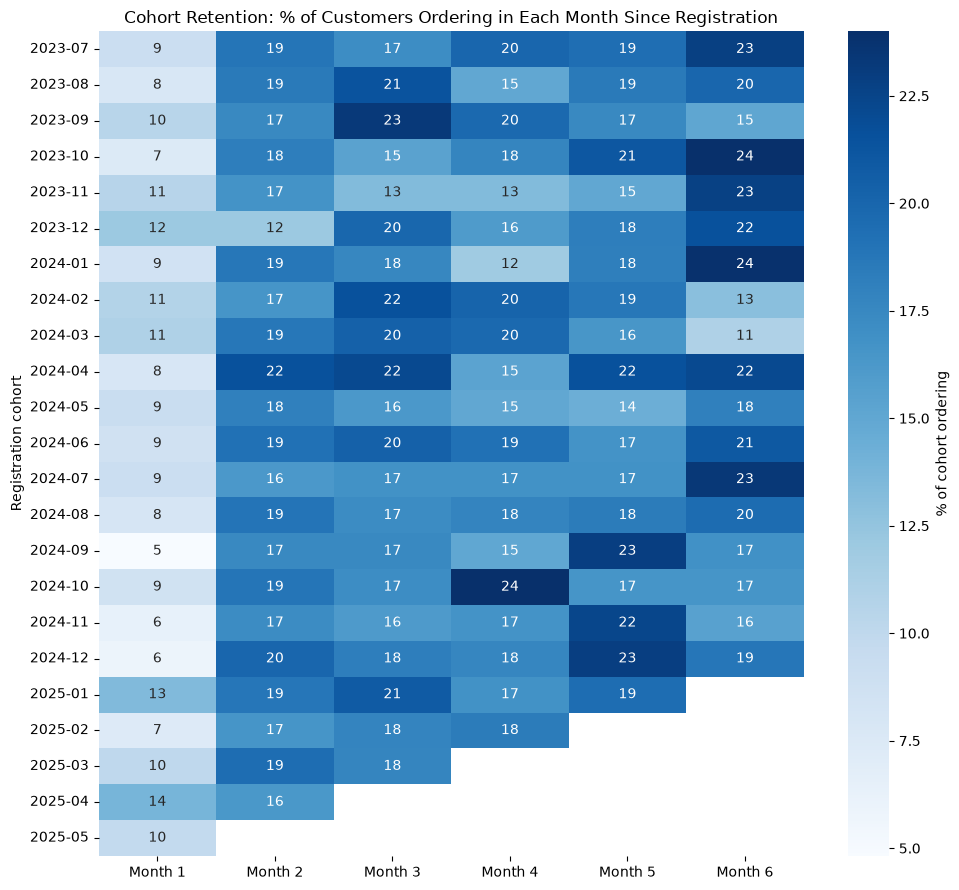

Month 1    9.20
Month 2   17.90
Month 3   18.50
Month 4   17.30
Month 5   18.70
Month 6   19.20
dtype: float64

In [16]:
active = oc.groupby(["cohort", "month_no"])["customer_id"].nunique().unstack().fillna(0)
for coh in active.index:
    for m in active.columns:
        if coh + (m - 1) > last:
            active.loc[coh, m] = np.nan

retention = active.div(cohort_size, axis=0) * 100
retention.columns = [f"Month {m}" for m in retention.columns]

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(retention, annot=True, fmt=".0f", cmap="Blues",
            cbar_kws={"label": "% of cohort ordering"}, ax=ax)
ax.set_title("Cohort Retention: % of Customers Ordering in Each Month Since Registration")
ax.set_ylabel("Registration cohort"); ax.set_xlabel("")
plt.tight_layout()
plt.savefig("charts/11_cohort_retention.png", dpi=150)
plt.show()

retention.mean().round(1)

**Observation:** About 18% of customers in each cohort place an order in any month after registering, and this stays flat from Month 2 to Month 6, so there is no visible drop-off. Month 1 is lower (about 9%) only because customers register part-way through the month. Cohorts perform similarly, which suggests ordering is driven by a steady share of repeat customers, not by when they joined. Note: 20.5% of orders are dated before the customer's registration date, so only orders on or after registration were counted.